# Distributed Quantum Reservoir Computing — reproduction notebook

**Paper:** Liliopoulos *et al.*, arXiv:2605.04991 (2026). Paper, claims and verdicts: [README](README.md); choices and naming: [`docs/reproduction_details.md`](docs/reproduction_details.md).

**What we found, and where the evidence is:**
1. **The paper's numbers reproduce** (Section 2).
2. **But the gain is not quantum:** it comes from the kernel readout, and the same kernel without any reservoir does as well (Section 3).
3. **What holds is the distributed architecture:** it carries over to photonics (Section 4) and is easy to distribute (Section 5).

The quantum advantage we hoped to confirm did not appear in our setting. The paper's architectural idea, small independent quantum circuits combined classically, is simple and works as described, and it opens several research directions (Section 5).

In [1]:
import copy, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

warnings.filterwarnings("ignore")

# Locate the paper folder (this notebook lives in papers/distributed_qrc/).
PAPER_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lib" / "runner.py").exists() and p.name == "distributed_qrc")
REPO_ROOT = PAPER_DIR.parents[1]
for path in (str(REPO_ROOT), str(PAPER_DIR.parent)):
    if path not in sys.path:
        sys.path.insert(0, path)

from runtime_lib.config import deep_update, load_config
from runtime_lib.dtypes import resolve_config_dtypes

# Every scientific computation below goes through the reproduction library in lib/.
from distributed_qrc.lib import runner
from distributed_qrc.lib.data import build_forecast_data
from distributed_qrc.lib.kernels import bloch_vectors, kernel_block
from distributed_qrc.lib.noise import IDEAL
from distributed_qrc.lib.quantum_neuron import neuron_expectations, neuron_functional
from distributed_qrc.lib.photonic_merlin import PhotonicKernelMap, build_neuron_layer, state_gram

RESULTS = PAPER_DIR / "results" / "data"
COLORS = {"quantum": "tab:blue", "classical": "tab:green", "merlin": "tab:red", "paper": "black", "b0": "tab:gray"}
ARCHS = {"srsr": "E1", "mrsr": "E2", "srmr": "E3", "mrmr": "E4"}
torch.set_num_threads(4)
START = time.perf_counter()
print("paper folder:", PAPER_DIR.relative_to(REPO_ROOT), "| torch", torch.__version__, "| CPU only:", not torch.cuda.is_available())

paper folder: papers/distributed_qrc | torch 2.12.1 | CPU only: True


In [2]:
def load_paper_config(*overlays: str) -> dict:
    # Same resolution as implementation.py: defaults.json, then each named overlay.
    cfg = load_config(PAPER_DIR / "configs" / "defaults.json")
    for name in overlays:
        deep_update(cfg, load_config(PAPER_DIR / "configs" / name))
    cfg = resolve_config_dtypes(copy.deepcopy(cfg))
    cfg["device"] = "cpu"
    return cfg

def show(df: pd.DataFrame, floatfmt: str = "{:.4f}") -> None:
    display(df.style.format(floatfmt, subset=df.select_dtypes("float").columns).hide(axis="index"))

def read_json(name: str):
    return json.loads((RESULTS / name).read_text())

## 1. Task, data and protocol

Forecast the next hourly Greek electricity load from the last 4 hours (data and splits: README). Every hyperparameter is chosen on the evaluation split and the test split is used once; results are mean ± std over seeds 0, 1, 2.

In [3]:
cfg = load_paper_config()
data = build_forecast_data(cfg)
meta = data.metadata
rows = [{"split": s, "raw values": meta["splits"][s]["raw_values"], "windows": data.inputs[s].shape[0],
         "first day": meta["splits"][s]["first_day"], "target mean (norm.)": float(data.targets[s].mean())} for s in ("train", "eval", "test")]
show(pd.DataFrame(rows), "{:.3f}")
print("series length:", meta["length"], "| fingerprint OK:", meta["fingerprint_sha256"][:12], "| window shape:", data.inputs["train"].shape)

split,raw values,windows,first day,target mean (norm.)
train,24539,24535,2020-10-22,0.516
eval,5258,5254,2023-08-10,0.470
test,5267,5263,2024-03-16,0.474


series length: 35064 | fingerprint OK: eca5bc5197fd | window shape: (24535, 4)


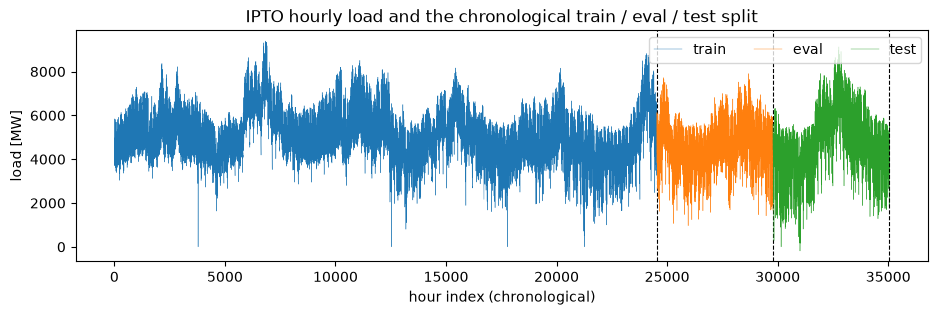

In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
offset = 0
for split, color in (("train", "tab:blue"), ("eval", "tab:orange"), ("test", "tab:green")):
    y = data.denormalize(split, data.targets[split])
    ax.plot(np.arange(offset, offset + y.size), y, lw=0.3, color=color, label=split)
    offset += y.size
    ax.axvline(offset, color="k", lw=0.8, ls="--")
ax.set_xlabel("hour index (chronological)"); ax.set_ylabel("load [MW]"); ax.set_title("IPTO hourly load and the chronological train / eval / test split")
ax.legend(loc="upper right", ncol=3); plt.show()

**What to take from it:** the split is chronological, so every model is trained and tuned on the past and tested on the last seven months (spring to autumn 2024), never on data it has seen. The load follows daily and seasonal cycles and changes smoothly from one hour to the next, which is why even simple forecasts from the last 4 hours are already accurate; the few drops to zero or below are data artefacts kept as published.

## 2. The paper's numbers reproduce

Our code uses fast, exact formulas instead of simulating the circuits gate by gate. We first check that they give the same values as Qiskit simulating the paper's circuits (Figs. 2 and 3).

In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

def qiskit_neuron(x, w):
    # Fig. 2, gate for gate: RX encoding, then 2 blocks of RX(w) and a CX-RZ-CX ladder.
    qc = QuantumCircuit(4)
    for q in range(4): qc.rx(x[q], q)
    for _ in range(2):
        for q in range(4): qc.rx(w[q], q)
        for t in range(1, 4):
            qc.cx(t - 1, t); qc.rz(w[t - 1] - w[t], t); qc.cx(t - 1, t)
    return qc

def qiskit_feature_map(x, n):
    # Fig. 3: 2 blocks of L layers of [H, P(2x)].
    L = int(np.ceil(len(x) / n)); pad = np.zeros(L * n); pad[: len(x)] = x
    qc = QuantumCircuit(n)
    for _ in range(2):
        for layer in range(L):
            for q in range(n): qc.h(q); qc.p(2 * pad[layer * n + q], q)
    return qc

rng = np.random.default_rng(0)
neuron_err, kernel_err = [], []
for _ in range(20):
    x, w = rng.uniform(-1, 1, 4), rng.uniform(0, 2 * np.pi, 4)
    ours = neuron_expectations(neuron_functional(w, IDEAL, "z_all")[None], x[None, None, :])[0, 0]
    ref = Statevector(qiskit_neuron(x, w)).expectation_value(SparsePauliOp("ZZZZ")).real
    neuron_err.append(abs(ours - ref))
    xa, xb = rng.uniform(-1, 1, (2, 20))
    ours_k = float(kernel_block(torch.from_numpy(bloch_vectors(xa[None], 10)), torch.from_numpy(bloch_vectors(xb[None], 10)), 1.0)[0, 0])
    ref_k = abs(Statevector(qiskit_feature_map(xa, 10)).inner(Statevector(qiskit_feature_map(xb, 10)))) ** 2
    kernel_err.append(abs(ours_k - ref_k))
print(f"quantum neuron, our formula vs Qiskit circuit: largest difference {max(neuron_err):.0e} over 20 random neurons")
print(f"quantum kernel, our formula vs Qiskit circuit: largest difference {max(kernel_err):.0e} over 20 random pairs (10 qubits)")
print("differences of order 1e-16 are rounding errors of 64-bit floats: the values are identical")
assert max(neuron_err) < 1e-10 and max(kernel_err) < 1e-10

quantum neuron, our formula vs Qiskit circuit: largest difference 4e-16 over 20 random neurons
quantum kernel, our formula vs Qiskit circuit: largest difference 6e-17 over 20 random pairs (10 qubits)
differences of order 1e-16 are rounding errors of 64-bit floats: the values are identical


The formulas compute exactly the paper's circuits. Below, every reproduced cell (full data, 3 seeds) next to the paper's value, for the fully quantum model and the paper's baseline B0:

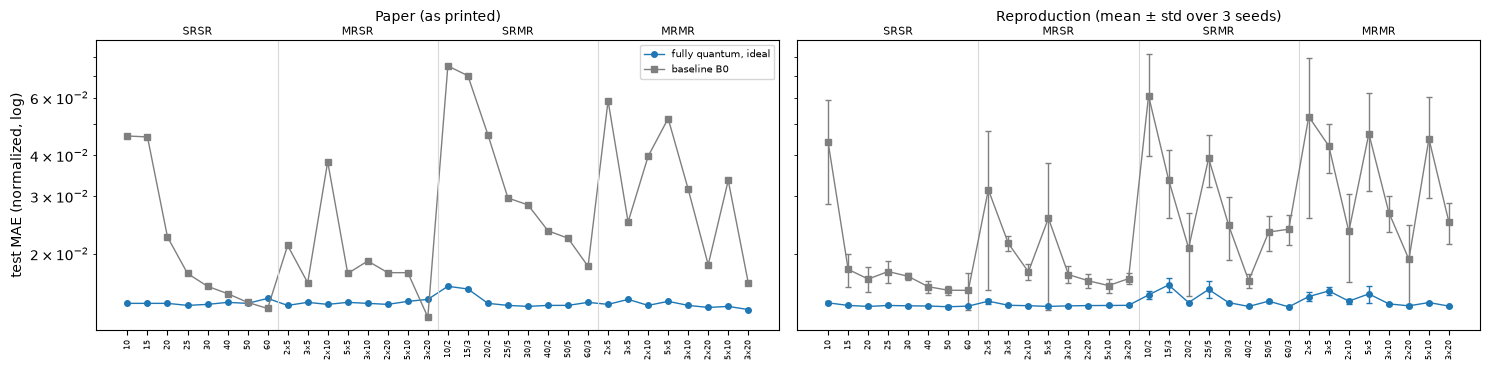

In [6]:
def total_neurons(config):
    # "10" (SRSR), "10/2" (SRMR: neurons / readouts) or "2x5" (MRSR, MRMR: reservoirs x neurons)
    if "x" in config:
        k, n = config.split("x")
        return int(k) * int(n)
    return int(config.split("/")[0])

grid = pd.concat(
    pd.read_csv(RESULTS / f"{arch}_vs_paper.csv", dtype={"configuration": str})
    .assign(order=lambda d: d.configuration.map(total_neurons))
    .sort_values("order", kind="stable")
    for arch in ARCHS
)
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, side in zip(axes, ("Paper (as printed)", "Reproduction (mean ± std over 3 seeds)")):
    for cell, c, m, label in (("quantum_ideal|quantum_kernel_ideal", COLORS["quantum"], "o", "fully quantum, ideal"), ("classical|linear", COLORS["b0"], "s", "baseline B0")):
        g = grid[(grid.reservoir + "|" + grid.readout) == cell].reset_index(drop=True)
        x = np.arange(len(g))
        if side.startswith("Paper"):
            ax.plot(x, g.mae_paper, color=c, marker=m, ms=4, lw=1, label=label)
        else:
            ax.errorbar(x, g.mae_ours, yerr=g.mae_ours_std, color=c, marker=m, ms=4, lw=1, capsize=2, label=label)
    for i, arch in enumerate(ARCHS):
        if i:
            ax.axvline(8 * i - 0.5, color="0.85", lw=0.8)
        ax.text(8 * i + 3.5, 1.02, arch.upper(), transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
    ax.set_xticks(x, g.configuration, rotation=90, fontsize=6); ax.set_yscale("log"); ax.set_title(side, fontsize=10, pad=14)
axes[0].set_ylabel("test MAE (normalized, log)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

The fully quantum cells match the paper (test MAE median deviation 2.6 %, 26/32 sizes within 5 %). B0 varies a lot from seed to seed, which explains its larger gaps. The paper's headline compares the best quantum or hybrid cell with B0 (paper values computed from its tables with the same rule):

In [7]:
head = read_json("headline_statistics.json")
rows = []
for arch in ARCHS:
    p, o = head["paper"][arch]["mae"], head["ours"][arch]
    pr, ev = o["paper_rule"]["mae"], o["eval_selected"]["mae"]
    rows.append({"architecture": arch.upper(), "paper, average": p["average"], "ours, average": pr["average_mean"], "± std": pr["average_std"],
                 "ours, eval selection": ev["average_mean"], "paper, peak": p["peak"], "ours, peak": pr["peak_mean"], "peak ± std": pr["peak_std"]})
df = pd.DataFrame(rows)
display(df.style.format({c: "{:.1%}" for c in df.columns if c != "architecture"}).hide(axis="index"))

architecture,"paper, average","ours, average",± std,"ours, eval selection","paper, peak","ours, peak",peak ± std
SRSR,28.5%,23.4%,1.5%,22.6%,69.2%,64.9%,12.3%
MRSR,24.7%,26.2%,3.6%,24.5%,63.4%,57.9%,17.4%
SRMR,54.2%,44.1%,3.1%,43.8%,78.8%,75.5%,6.5%
MRMR,52.1%,51.8%,5.9%,51.6%,76.1%,75.4%,7.0%


**Result:** against B0, our average reductions (23–52 %) are of the same order as the paper's, and choosing the best cell on the evaluation split instead of the test split changes them by less than 2 points. The paper's numbers reproduce.

## 3. The gain is not quantum

B0 has a linear readout, while the best quantum models have a kernel readout. The additional classical models (README, *Fair Baselines*) use the same inputs, splits, seeds and evaluation; the best model of each side is chosen on the evaluation split. The figure shows, per size, the best quantum model, the best classical one, B0 and the paper's kernel without any reservoir (dashed line).

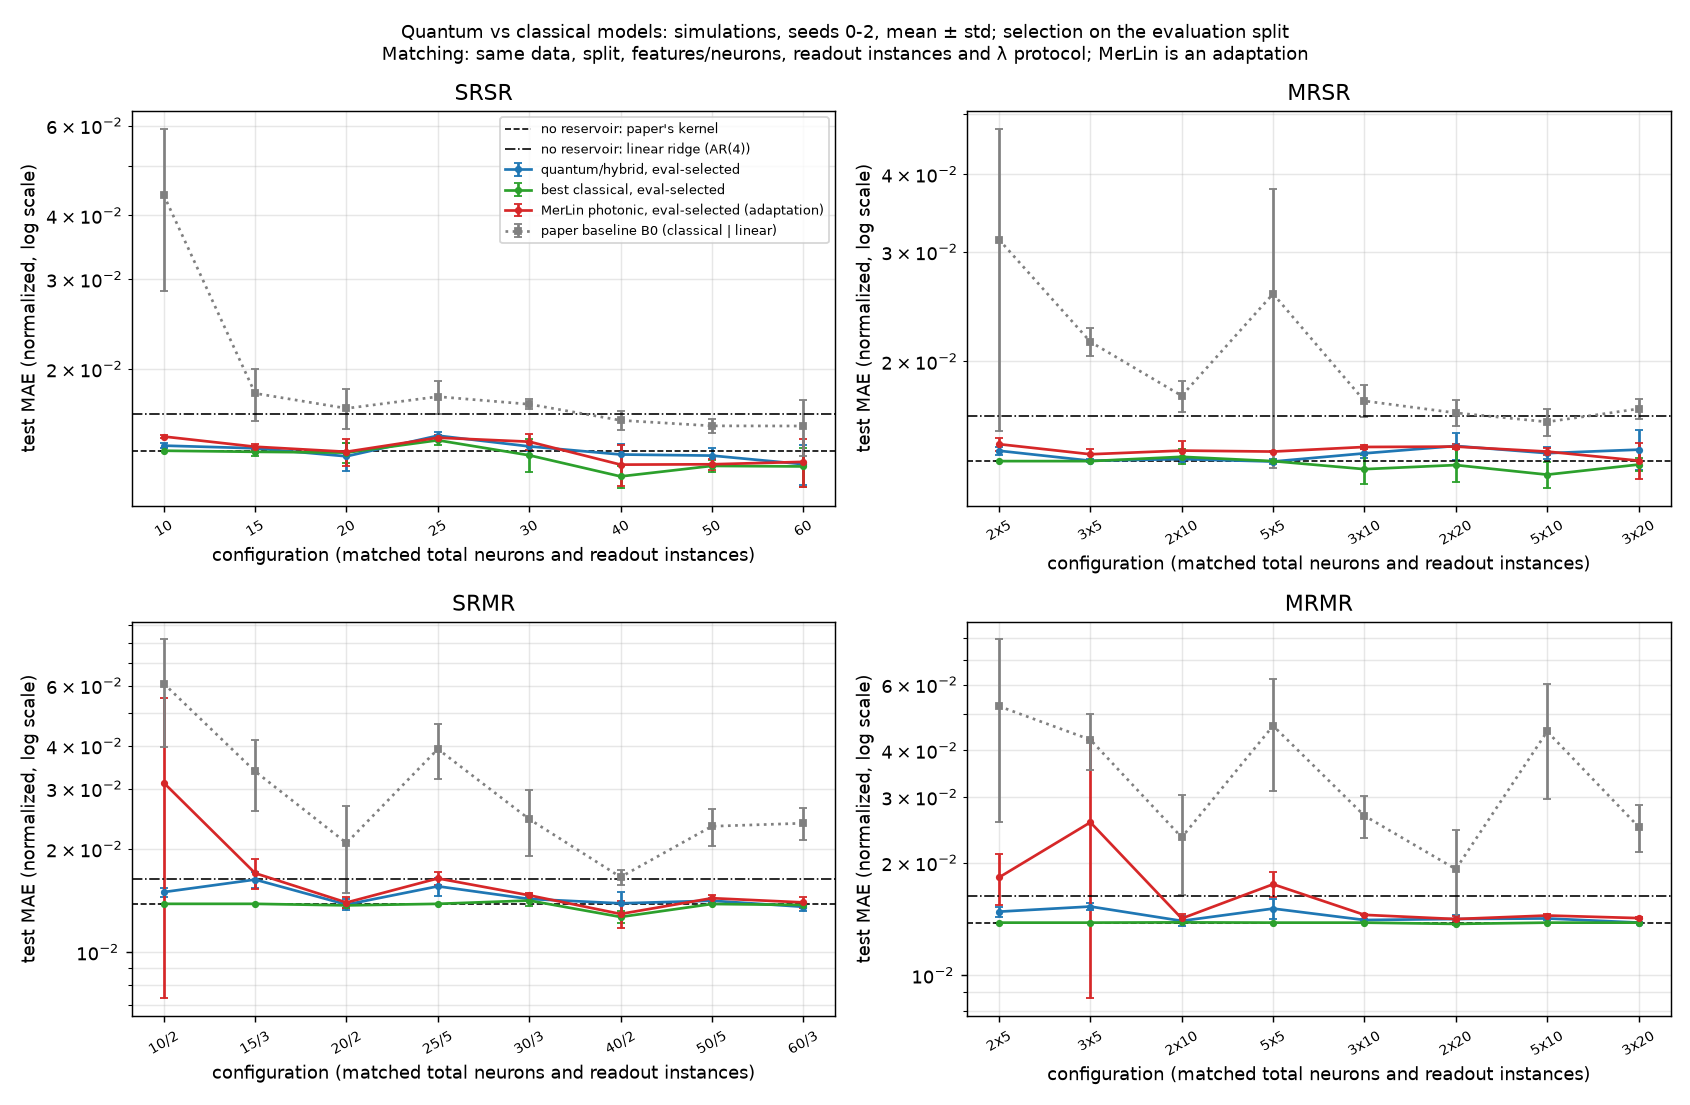

architecture,best quantum vs best classical (better / tie / worse),MAE change vs best classical,kernel without reservoir vs best quantum (better / tie / worse),quantum vs RBF kernel on the same classical features
SRSR,0 / 6 / 2,+3.1%,3 / 5 / 0,0 / 8 / 0
MRSR,0 / 6 / 2,+3.9%,2 / 6 / 0,0 / 8 / 0
SRMR,0 / 5 / 3,+6.3%,4 / 4 / 0,0 / 8 / 0
MRMR,0 / 4 / 4,+4.4%,4 / 4 / 0,0 / 8 / 0


In [8]:
display(Image(filename=str(PAPER_DIR / "results" / "fair_comparison.png"), width=1100))

fair = read_json("fair_comparison.json")

def verdict(mean_a, std_a, mean_b, std_b):
    # The comparison rule declared before the runs: better if lower by more than 2 pooled seed std.
    gap, pooled = mean_a - mean_b, np.sqrt((std_a**2 + std_b**2) / 2)
    return "better" if gap < -2 * pooled else "worse" if gap > 2 * pooled else "tie"

rows = []
for arch in ARCHS:
    a = fair["architectures"][arch]
    best_classical = a["claims"]["C1_vs_fair_classical"]["counts"]
    same_features = a["claims"]["C2_classical_features"]["counts"]
    no_reservoir = [verdict(a["per_configuration"][c]["raw_lags|quantum_kernel_ideal"]["mean"], a["per_configuration"][c]["raw_lags|quantum_kernel_ideal"]["std"],
                            sel["quantum"]["test_mae"]["mean"], sel["quantum"]["test_mae"]["std"]) for c, sel in a["eval_selected"].items()]
    rows.append({"architecture": arch.upper(),
                 "best quantum vs best classical (better / tie / worse)": f"{best_classical['better']} / {best_classical['tie']} / {best_classical['worse']}",
                 "MAE change vs best classical": f"{-a['E7_headline_vs_fair_classical']['mae']['average']['mean']:+.1%}",
                 "kernel without reservoir vs best quantum (better / tie / worse)": f"{no_reservoir.count('better')} / {no_reservoir.count('tie')} / {no_reservoir.count('worse')}",
                 "quantum vs RBF kernel on the same classical features": f"{same_features['better']} / {same_features['tie']} / {same_features['worse']}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

**Result:** the best quantum model is never better than the best classical one (0/32 sizes); the paper's kernel applied directly to the last 4 hours, without any reservoir, is as good as or better than the best quantum model everywhere; and on the same classical features, a standard RBF kernel does as well as the quantum kernel. The gain comes from using a kernel readout, not from the quantum components.

These conclusions do not depend on secondary choices (normalization, data artefacts), and the gaps with the paper are not explained by a missing intercept or by finite shots:

In [9]:
verdicts = read_json("robustness_verdicts.json")
rows = []
for cand, v in verdicts["S2-R2"].items():
    rows.append({"check": "robustness to " + ", ".join(f"{k} = {v}" for k, v in json.loads(cand).items()), "result": f"headline Δ {v['headline_delta']:+.3f} (unchanged: {v['headline_unchanged']}); cells moved beyond 1 std: {sum(x['material'] for x in v['cells'].values())}/{len(v['cells'])}"})
rows.append({"check": "missing-intercept hypothesis (linear cells)", "result": f"{verdicts['S5-R2']['cells_within_seed_std']}/{verdicts['S5-R2']['cells']} cells explained -> {verdicts['S5-R2']['intercept_hypothesis']}"})
rows.append({"check": "noise scale closest to the paper's degradation", "result": f"×{json.loads(verdicts['S4-R2']['closest_scale'])['noise_scale']} (any scale fully consistent: {verdicts['S4-R2']['any_consistent']})"})
rows.append({"check": "finite shots explain the noisy gap", "result": f"supported: {verdicts['S3-R2_H1_supported']} (shots over-degrade)"})
for arch, g in verdicts["GAP-CLASSICAL-R2"].items():
    rows.append({"check": f"B0 seed spread, {arch.upper()} (20 seeds)", "result": f"paper value inside our range in {g['inside']}/{g['configurations']} configurations"})
display(pd.DataFrame(rows).style.hide(axis="index"))

check,result
robustness to normalization = per_split,headline Δ -0.003 (unchanged: True); cells moved beyond 1 std: 1/4
robustness to artifact_handling = interpolate,headline Δ +0.004 (unchanged: True); cells moved beyond 1 std: 2/4
missing-intercept hypothesis (linear cells),3/24 cells explained -> rejected
noise scale closest to the paper's degradation,×10 (any scale fully consistent: False)
finite shots explain the noisy gap,supported: False (shots over-degrade)
"B0 seed spread, SRSR (20 seeds)",paper value inside our range in 4/8 configurations
"B0 seed spread, MRSR (20 seeds)",paper value inside our range in 6/8 configurations
"B0 seed spread, SRMR (20 seeds)",paper value inside our range in 7/8 configurations
"B0 seed spread, MRMR (20 seeds)",paper value inside our range in 7/8 configurations


## 4. The architecture carries over to photonics (MerLin)

Each quantum neuron becomes a frozen 2-photon chip, and the kernel a 2-photon chip (README, *Photonic Assessment*). First, a check of MerLin's photonic outputs against an independent Perceval computation:

In [10]:
import itertools
import perceval as pcvl

def perceval_amplitude(u, s_in, s_out):
    backend = pcvl.BackendFactory.get_backend("SLOS"); backend.set_circuit(pcvl.Unitary(pcvl.Matrix(u)))
    backend.set_input_state(pcvl.BasicState(s_in)); return backend.prob_amplitude(pcvl.BasicState(s_out))

def circuit_unitary(circuit, values):
    params = sorted((p for p in circuit.get_parameters(all_params=True) if p.name.startswith("px")), key=lambda p: int(p.name[2:]))
    for p, v in zip(params, values): p.set_value(float(v))
    return np.array(circuit.compute_unitary(use_symbolic=False))

layer = build_neuron_layer(1.0, np.random.SeedSequence(5))
x = np.random.default_rng(1).uniform(-1, 1, (3, 4))
with torch.no_grad():
    merlin_out = layer(torch.from_numpy(x)).numpy()
outputs = [o for o in itertools.product(range(3), repeat=4) if sum(o) == 2]
err_post, err_raw = [], []
for row, xi in zip(merlin_out, x):
    u = circuit_unitary(layer.circuit, xi)
    probs = {o: abs(perceval_amplitude(u, [1, 0, 1, 0], list(o))) ** 2 for o in outputs}
    free = {o: p for o, p in probs.items() if max(o) <= 1}
    post = [sum(p * o[m] for o, p in free.items()) / sum(free.values()) for m in range(4)]
    raw = [sum(p * o[m] for o, p in probs.items()) for m in range(4)]
    err_post.append(np.abs(row - post).max()); err_raw.append(np.abs(row - raw).max())
print(f"MerLin UNBUNCHED <n_i> vs Perceval, post-selected on 2 clicks: max |error| = {max(err_post):.1e}")
print(f"MerLin UNBUNCHED <n_i> vs Perceval, no post-selection     : max |error| = {max(err_raw):.1e}  (so it IS post-selected)")

km = PhotonicKernelMap(n_features=10, n_modes=10, n_photons=2, scale=2.0, blocks=2, sequence=np.random.SeedSequence(3))
G = state_gram(km.states(np.random.default_rng(0).uniform(-1, 1, (50, 10)))).numpy()
print(f"photonic kernel: Fock dimension {km.states(np.zeros((1, 10))).shape[1]}, Gram symmetric {np.allclose(G, G.T)}, unit diagonal {np.allclose(np.diag(G), 1)}, min eigenvalue {np.linalg.eigvalsh(G).min():.1e}")

MerLin UNBUNCHED <n_i> vs Perceval, post-selected on 2 clicks: max |error| = 1.1e-16
MerLin UNBUNCHED <n_i> vs Perceval, no post-selection     : max |error| = 5.4e-02  (so it IS post-selected)
photonic kernel: Fock dimension 55, Gram symmetric True, unit diagonal True, min eigenvalue 4.5e-01


Then the full photonic grids (3 seeds) against the gate model; the adaptation counts as preserving the gate model if it stays within 10 % or 2 seed std in at least 6/8 sizes (declared before the runs):

In [11]:
merlin = read_json("merlin_comparison.json")
rows = []
for arch in ARCHS:
    m = merlin[arch]
    rows.append({"architecture": arch.upper(),
                 "photonic+photonic kernel vs gate full-quantum": f"{m['a_full_quantum']['verdict']} ({m['a_full_quantum']['preserved_count']}/8, median {m['a_full_quantum']['median_relative_delta']:+.1%})",
                 "photonic reservoir + linear vs gate + linear": f"{m['c_reservoir_linear']['verdict']} ({m['c_reservoir_linear']['median_relative_delta']:+.1%})",
                 "headline vs B0 (MerLin / gate)": f"{m['d_headline']['merlin']['mae']['average_mean']:.1%} / {m['d_headline']['r2_ideal']['mae']['average_mean']:.1%}",
                 "MerLin vs additional classical: better": f"{fair['architectures'][arch]['claims']['MERLIN_vs_fair_classical']['counts']['better']}/8"})
display(pd.DataFrame(rows).style.hide(axis="index"))

architecture,photonic+photonic kernel vs gate full-quantum,photonic reservoir + linear vs gate + linear,headline vs B0 (MerLin / gate),MerLin vs additional classical: better
SRSR,"preserves (8/8, median +2.8%)",preserves (-3.1%),23.1% / 23.2%,0/8
MRSR,"preserves (8/8, median +2.5%)",preserves (-2.3%),25.1% / 26.1%,0/8
SRMR,"preserves (8/8, median +3.3%)",preserves (-1.1%),40.7% / 44.1%,0/8
MRMR,"preserves (8/8, median +3.0%)",preserves (-0.6%),46.8% / 51.8%,0/8


**Result:** the photonic models behave like the gate models in all four architectures (kernel cells 2–3 % worse, reservoir cells slightly better), with the same limit: no gain over the classical baselines.

## 5. A simple architecture to distribute, and what it opens

In MRMR, each branch (a reservoir and its own readout) needs only the last 4 hours, and only its forecast leaves it. Below, the same MRMR model (3 reservoirs of 10 quantum neurons) computed in one process, then with each branch in its own process, as it would run on separate nodes or QPUs:

In [12]:
from concurrent.futures import ProcessPoolExecutor
from functools import partial

from distributed_qrc.lib.architectures import build_cell_spec
from distributed_qrc.lib.distributed import branch_forecast
from distributed_qrc.lib.noise import devices_for_components
from distributed_qrc.lib.readouts import merge_predictions

demo_cfg = load_paper_config(); demo_cfg["seed"] = 0
spec = build_cell_spec("mrmr", "3x10")  # 3 reservoirs of 10 quantum neurons, one readout each
mapping = demo_cfg["noise"]["mapping"]

# 1. As in the reproduction: one process computes the whole model.
t0 = time.perf_counter()
features = runner._reservoir_features(demo_cfg, data, spec, 0, "quantum_ideal", devices_for_components(3, mapping))
sequential, _ = runner._fit_cell(demo_cfg, data, spec, features, "linear", devices_for_components(3, mapping), "mrmr:3x10|quantum_ideal|linear")
seconds_one = time.perf_counter() - t0

# 2. Distributed: each branch (its reservoir and its readout) runs in its own process; only its forecast comes back.
t0 = time.perf_counter()
with ProcessPoolExecutor(max_workers=3) as pool:
    branches = list(pool.map(partial(branch_forecast, demo_cfg, data, spec, 0), range(3)))
distributed = merge_predictions([b["test"] for b in branches], demo_cfg["readout"]["merge"])
seconds_three = time.perf_counter() - t0

runs = pd.DataFrame([
    {"run": "one process", "seconds": seconds_one, "test MAE": np.abs(data.targets["test"] - sequential["test"]).mean()},
    {"run": "three processes, one per branch", "seconds": seconds_three, "test MAE": np.abs(data.targets["test"] - distributed).mean()},
])
display(runs.style.format({"seconds": "{:.1f}", "test MAE": "{:.4f}"}).hide(axis="index"))
print(f"largest difference between the two forecasts: {np.abs(distributed - sequential['test']).max():.0e} (floating-point rounding)")

run,seconds,test MAE
one process,4.1,0.0154
"three processes, one per branch",4.2,0.0154


largest difference between the two forecasts: 4e-13 (floating-point rounding)


**Result:** the distributed run gives the same forecast. Here the processes only add start-up time, but each branch could run on any machine or QPU without changing the model. This is what makes the paper's idea attractive: the cell above is the first step of our distributed-stack proof of concept, and the same architecture can host kernels that are hard to simulate, reservoirs with memory, harder tasks and real hardware (README, *Next Steps*).

## Conclusion

- **Reproduced:** the code computes the paper's circuits exactly, and the paper's numbers reproduce against its own baseline (Section 2).
- **Not confirmed:** the quantum advantage; a classical kernel without reservoir does as well (Section 3). The best model of the paper (C5) and its noisy degradation are not reproduced.
- **What holds:** the distributed architecture, in gate-based and photonic simulation, and easy to distribute (Sections 4 and 5).

**Verdict: partially reproduced.** The expected quantum gain did not appear, but the paper's architecture is simple, reproducible and a good basis for the directions above. Limitations: 3 seeds per cell, a noise model rebuilt from calibration medians, simulation only.

In [13]:
print(f"notebook executed in {time.perf_counter() - START:.0f} s on CPU")

notebook executed in 9 s on CPU
